In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='darkgrid')

In [2]:
data = pd.read_csv('data/train.csv', index_col='PassengerId')
data

,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
PassengerId,,,,,,,,,,,
1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...
887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S


In [3]:
data.describe()

,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [4]:
data.isnull().sum()

Survived      0
Pclass        0
Name          0
Sex           0
Age         177
SibSp         0
Parch         0
Ticket        0
Fare          0
Cabin       687
Embarked      2
dtype: int64

The `Age`, `Cabin` and `Embarked` features have null values. Need to be preprocessed.

## Primary visualizations

How many survived?

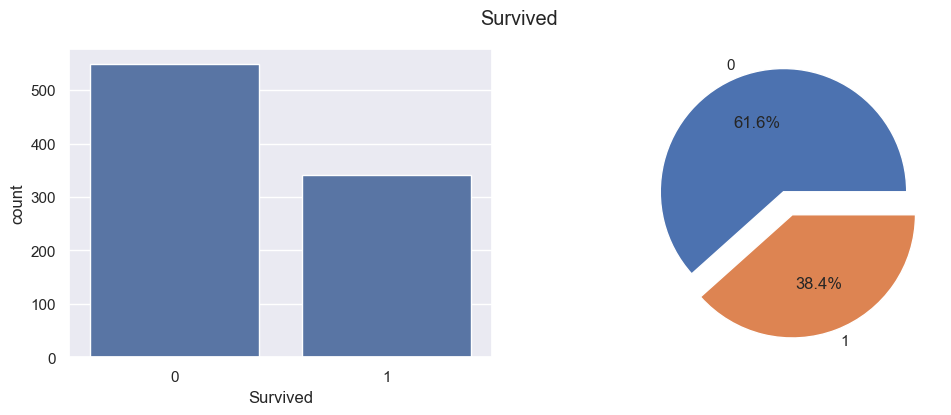

In [5]:
f, ax = plt.subplots(1, 2, figsize=(12,4))
sns.barplot(data["Survived"].value_counts(), ax= ax[0])
data["Survived"].value_counts().plot.pie(explode=[0.1,0.1], autopct='%1.1f%%', ax=ax[1])
f.suptitle("Survived")
None

### Numerical features distributions

count    714.000000
mean      29.699118
std       14.526497
min        0.420000
25%       20.125000
50%       28.000000
75%       38.000000
max       80.000000
Name: Age, dtype: float64

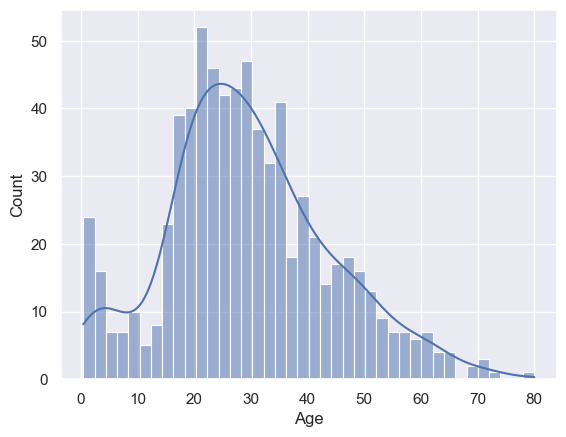

In [6]:
sns.histplot(data['Age'], kde=True, bins=40)
data['Age'].describe()

`Age` distribution looks like a **normal distribution**.

---

count    891.000000
mean      32.204208
std       49.693429
min        0.000000
25%        7.910400
50%       14.454200
75%       31.000000
max      512.329200
Name: Fare, dtype: float64

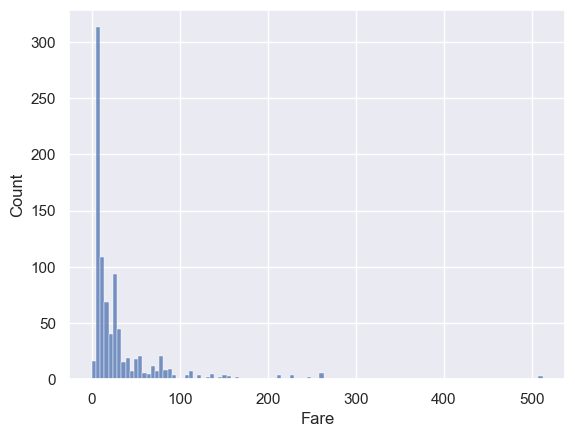

In [7]:
sns.histplot(data['Fare'])
data['Fare'].describe()

`Fare` distribution have a large std, because of some high-value variables.

---

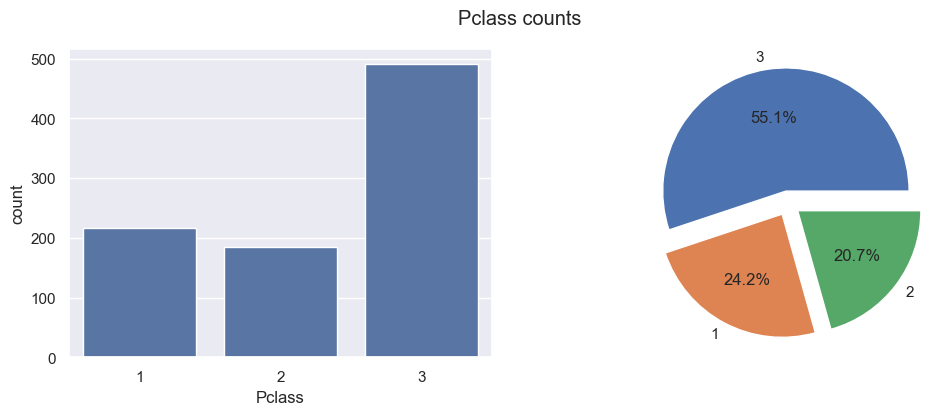

In [8]:
f, ax = plt.subplots(1, 2, figsize=(12,4))
sns.barplot(data["Pclass"].value_counts(), ax =ax[0])
data["Pclass"].value_counts().plot.pie(explode=[0.1,0.1,0.1], autopct='%1.1f%%', ax=ax[1])
f.suptitle("Pclass counts")
None

The majority or passengers had a 3rd class ticket.

---

### Some other statistic

Sex
male      0.647587
female    0.352413
Name: proportion, dtype: float64

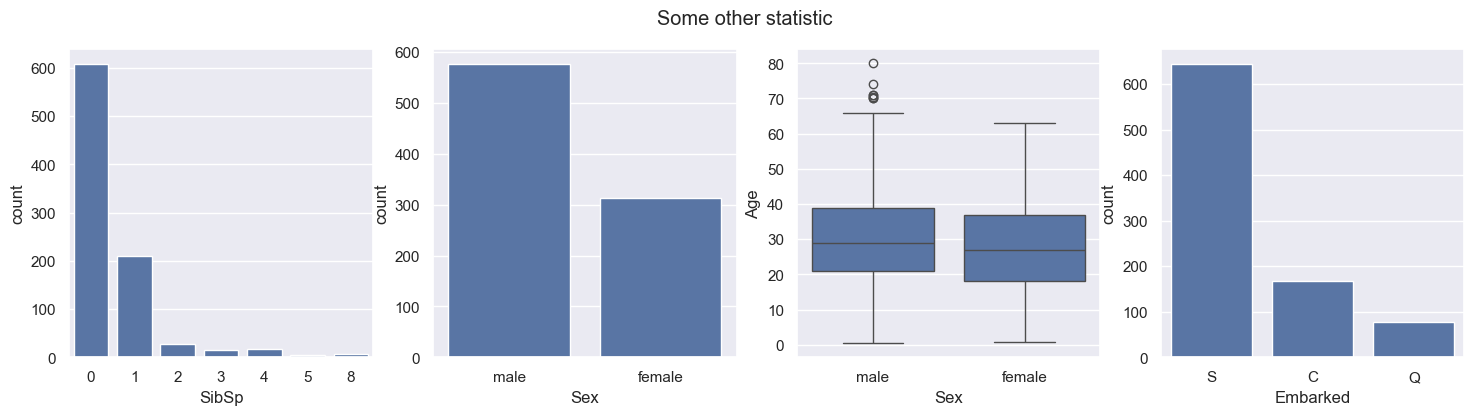

In [9]:
f, ax = plt.subplots(1, 4, figsize=(18,4))
sns.barplot(data["SibSp"].value_counts(), ax= ax[0])
sns.barplot(data["Sex"].value_counts(), ax= ax[1])
sns.boxplot(data=data, x='Sex', y='Age', ax=ax[2])
sns.barplot(data["Embarked"].value_counts(), ax= ax[3])
f.suptitle("Some other statistic")
data["Sex"].value_counts(normalize=True)

About 64% of passengers were male. Male and female had just about the same median age. Most of people had 0 or 1 sibling on the board.

## Lets check the relationship between features and the target

### Correlation matrix

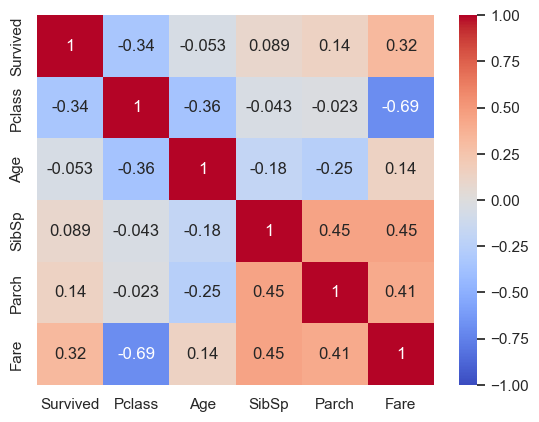

In [10]:
sns.heatmap(data.corr(numeric_only=True,method='spearman'), cmap='coolwarm', annot=True, vmin=-1, vmax=1, center=0)
None

The target `Survived` has a medium correlation with features `Pclass` and `Fare`

### Categorical features dependence of survival

Sex
female    0.742038
male      0.188908
Name: Survived, dtype: float64

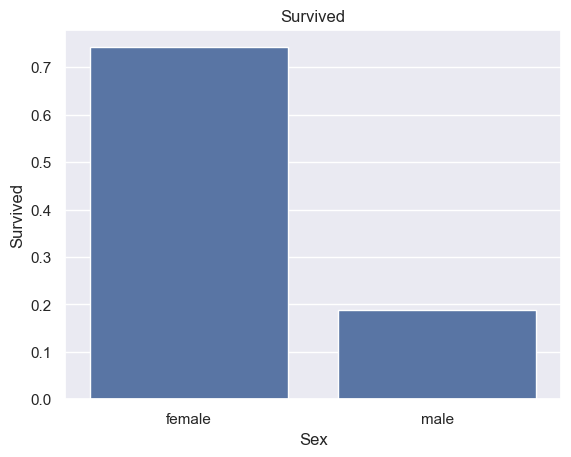

In [11]:
sns.barplot(data.groupby(['Sex'])['Survived'].mean()).set_title('Survived')
data.groupby(['Sex'])['Survived'].mean()

Among women, 74.2% survived. Among men, 18.9% survived.

Age
(0.0, 1.0]      0.857143
(1.0, 5.0]      0.633333
(5.0, 18.0]     0.410526
(18.0, 25.0]    0.333333
(25.0, 45.0]    0.412903
(45.0, 80.0]    0.368932
Name: Survived, dtype: float64

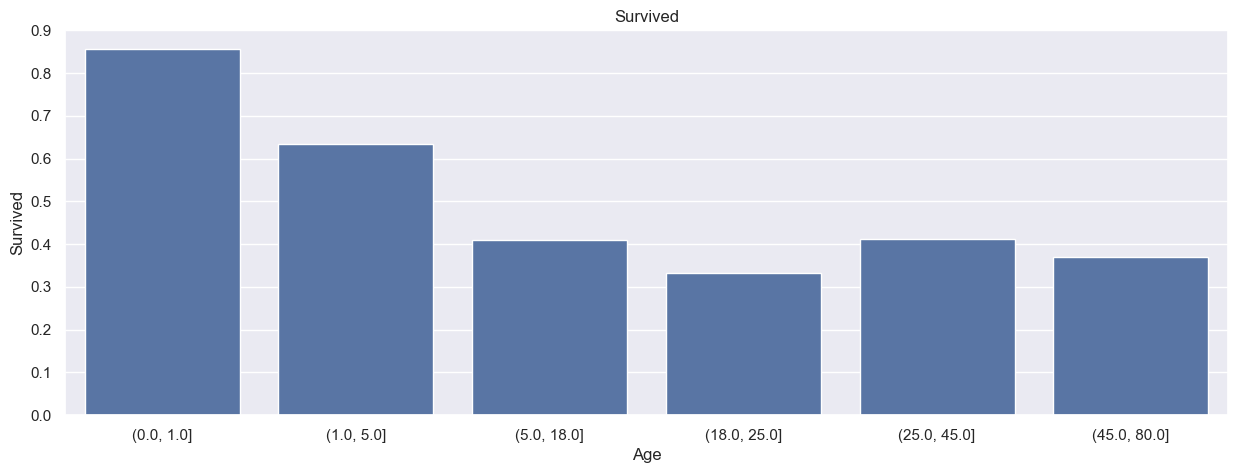

In [12]:
bins = [0, 1, 5, 18, 25, 45,data.Age.max()]
age_cuts = data.groupby(pd.cut(data.Age, bins)).Survived.mean()
plt.figure(figsize=(15,5))
sns.barplot(age_cuts).set_title('Survived')
age_cuts

Youngest passengers survived more often.

(Fare
 (-0.001, 7.91]     0.197309
 (7.91, 14.454]     0.303571
 (14.454, 31.0]     0.454955
 (31.0, 512.329]    0.581081
 Name: Survived, dtype: float64,
 Pclass
 1    0.629630
 2    0.472826
 3    0.242363
 Name: Survived, dtype: float64)

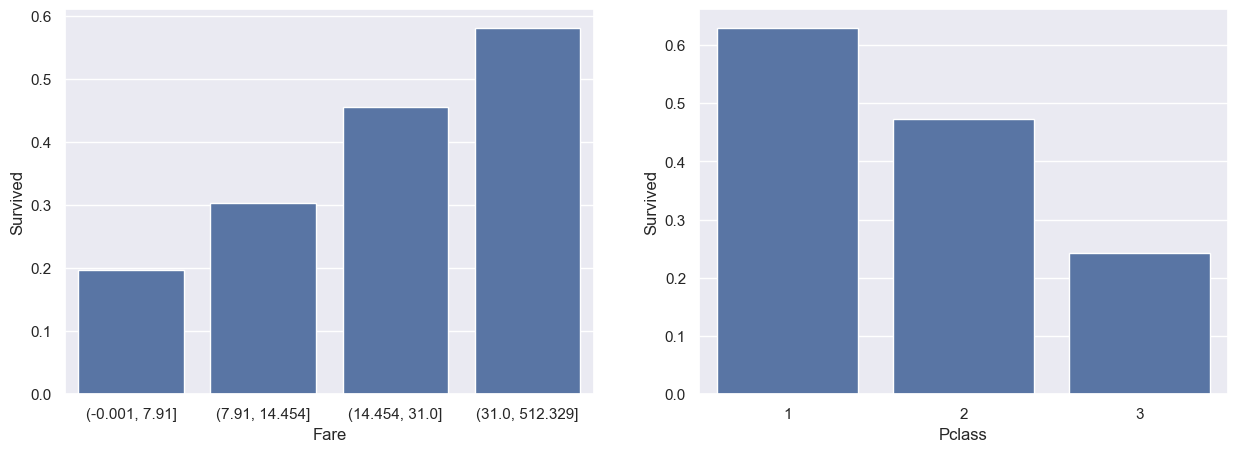

In [13]:
f, ax = plt.subplots(1,2, figsize=(15,5))
fare_cuts = data.groupby(pd.qcut(data.Fare, 4)).Survived.mean()
pclass_cuts = data.groupby('Pclass').Survived.mean()
sns.barplot(fare_cuts, ax=ax[0])
sns.barplot(pclass_cuts, ax=ax[1])
fare_cuts, pclass_cuts

Passengers with more expensive tickets from the 1st & 2nd class survived more often. Its not surprising because of strong correlation between `Fare` and `Pclass` 

### Some other regularities

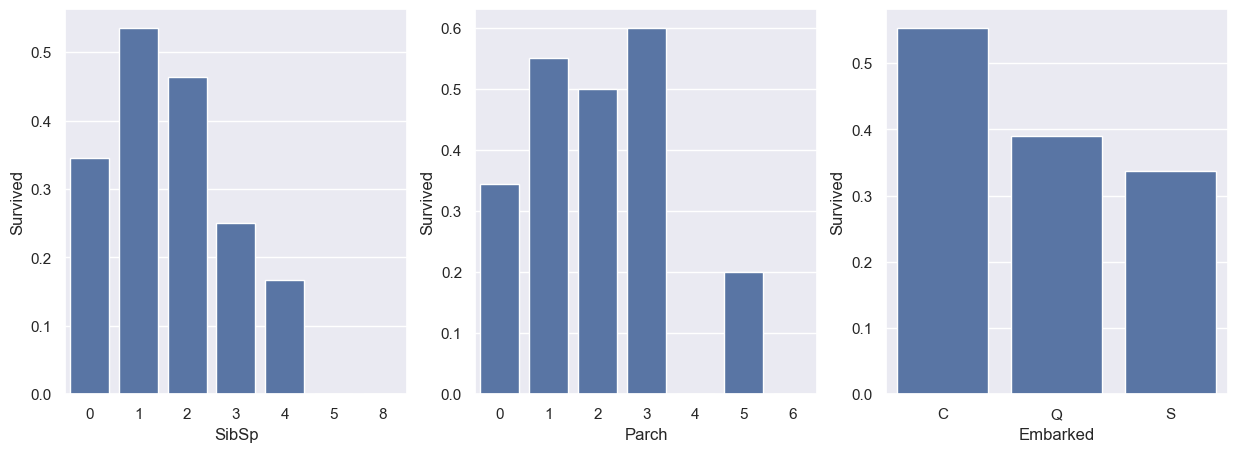

In [14]:
f, ax = plt.subplots(1,3, figsize=(15,5))
sibsp_cuts = data.groupby('SibSp').Survived.mean()
parch_cuts = data.groupby('Parch').Survived.mean()
embarked_cuts = data.groupby('Embarked').Survived.mean()
sns.barplot(sibsp_cuts, ax=ax[0])
sns.barplot(parch_cuts, ax=ax[1])
sns.barplot(embarked_cuts, ax=ax[2])
None

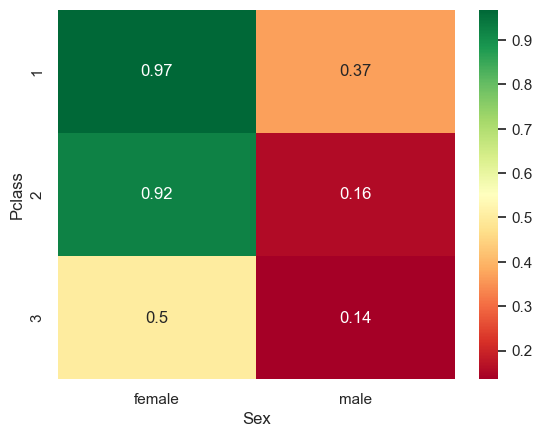

In [15]:
pivot_table = data.pivot_table(index='Pclass', columns='Sex', values='Survived')
sns.heatmap(pivot_table, cmap='RdYlGn', annot=True)
None

Almost all of the 1st and 2nd class female survived